**Name:** *Mohammed Nasser Almarhoon*

**ID:** *2240005893*

**Group:** *7MA2*

# Lab 9 - Morphological Operations

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'balls.png'

## Task 1: Apply Morphological Operations to a New Image

# Erosion Operations

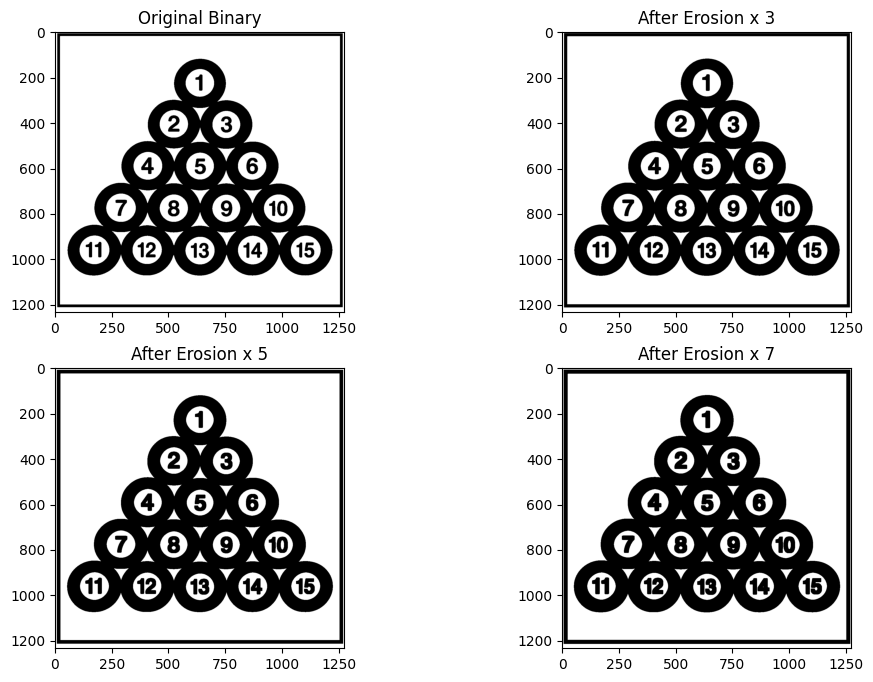

In [22]:
# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive erosion

kernel3 = np.ones((3, 3), np.uint8)
kernel5 = np.ones((5, 5), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)

# 4. Apply erosion
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img5 = cv2.erode(binary, kernel5, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Erosion x 3')
plt.subplot(2, 2, 3), plt.imshow(eroded_img5, 'gray'), plt.title('After Erosion x 5')
plt.subplot(2, 2, 4), plt.imshow(eroded_img7, 'gray'), plt.title('After Erosion x 7')

plt.show()

# **Dilation Operations**

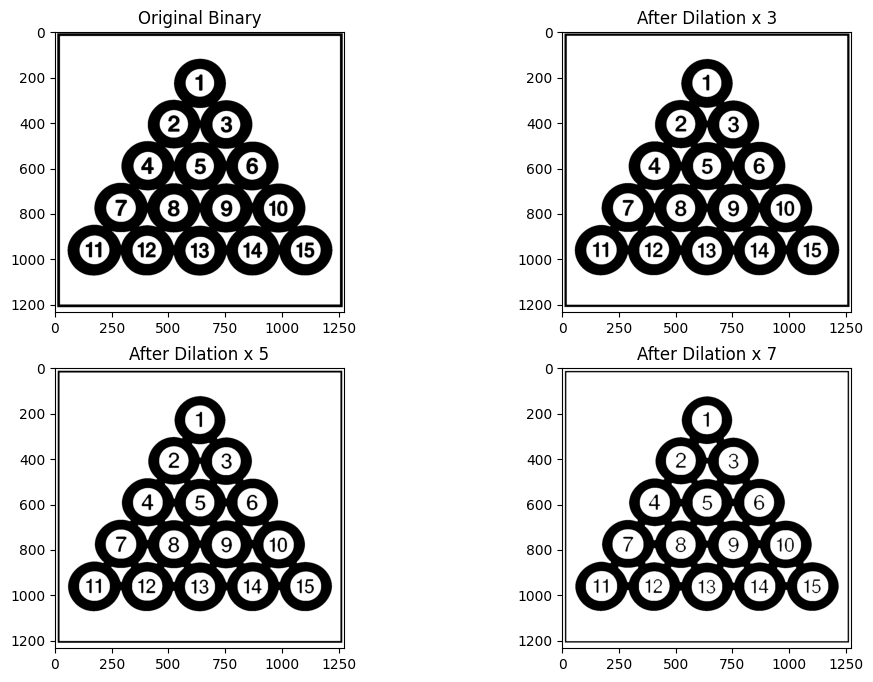

In [23]:
# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method works well for varying light)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define a 3x3 kernel (all ones), you can define kernel of size 5x5, 7x7, ... any odd x odd
# Larger kernels lead to more aggressive dilation

kernel3 = np.ones((3, 3), np.uint8)
kernel5 = np.ones((5, 5), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)

# 4. Apply dilation
# 'iterations' determines how many times the operation is repeated,
# ===> You can change iterations values to apply same process multiple times.

dilated_img3 = cv2.dilate(binary, kernel3, iterations=1)
dilated_img5 = cv2.dilate(binary, kernel5, iterations=1)
dilated_img7 = cv2.dilate(binary, kernel7, iterations=1)

# 5. Display comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary')
plt.subplot(2, 2, 2), plt.imshow(dilated_img3, 'gray'), plt.title('After Dilation x 3')
plt.subplot(2, 2, 3), plt.imshow(dilated_img5, 'gray'), plt.title('After Dilation x 5')
plt.subplot(2, 2, 4), plt.imshow(dilated_img7, 'gray'), plt.title('After Dilation x 7')

plt.show()

# **Morphological Open Operations**

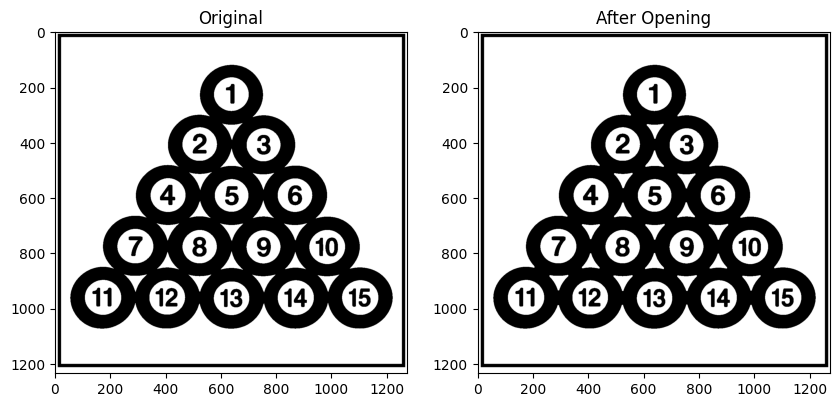

In [24]:
# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 5x5 square is a good starting point)
kernel = np.ones((5, 5), np.uint8)

# 3. Apply Opening
# This is equivalent to: dilate(erode(binary))

opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original')
plt.subplot(1, 2, 2), plt.imshow(opening, 'gray'), plt.title('After Opening')

plt.show()

# **Closing Morphological Operation**

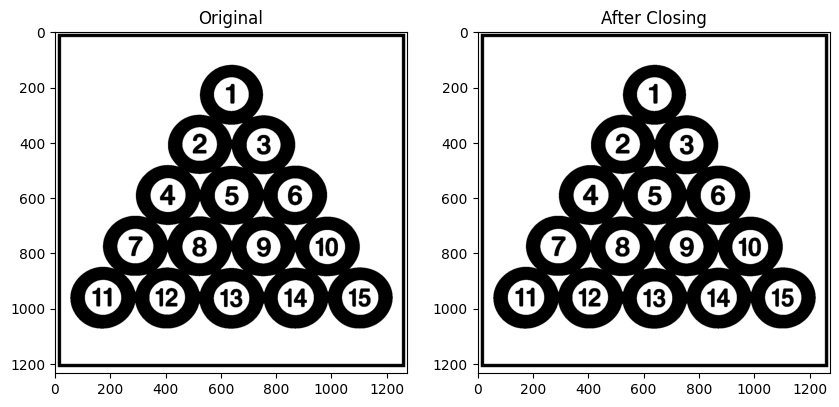

In [25]:
# 1. Load image and binarize
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define kernel (a 5x5 square is a good starting point)
kernel = np.ones((5, 5), np.uint8)

# 3. Apply Closing
# Effectively: cv2.erode(cv2.dilate(binary, kernel), kernel)

closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 4. Display comparison
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original')
plt.subplot(1, 2, 2), plt.imshow(closing, 'gray'), plt.title('After Closing')

plt.show()

## Task 2: Experiment with Structuring Elements

# Square Structuring Element

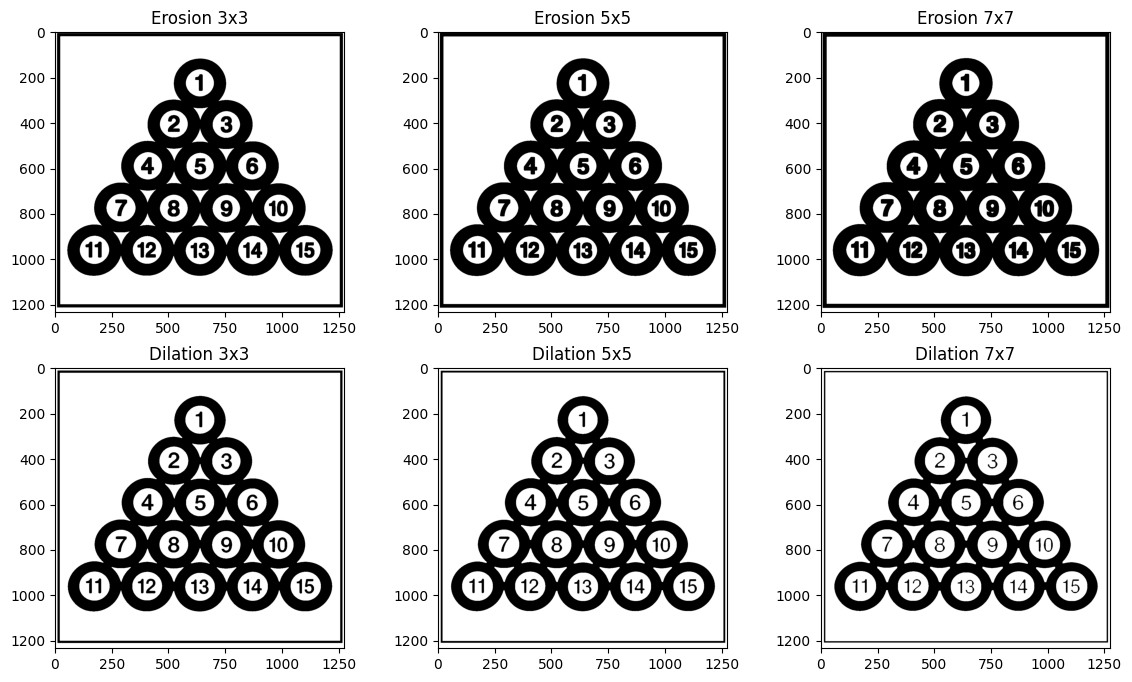

In [26]:
# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define square kernels
kernel3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
kernel5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
kernel7 = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))

# 4. Apply erosion and dilation
eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img5 = cv2.erode(binary, kernel5, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)

dilated_img3 = cv2.dilate(binary, kernel3, iterations=1)
dilated_img5 = cv2.dilate(binary, kernel5, iterations=1)
dilated_img7 = cv2.dilate(binary, kernel7, iterations=1)

# 5. Display comparison
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1), plt.imshow(eroded_img3, 'gray'), plt.title('Erosion 3x3')
plt.subplot(2, 3, 2), plt.imshow(eroded_img5, 'gray'), plt.title('Erosion 5x5')
plt.subplot(2, 3, 3), plt.imshow(eroded_img7, 'gray'), plt.title('Erosion 7x7')

plt.subplot(2, 3, 4), plt.imshow(dilated_img3, 'gray'), plt.title('Dilation 3x3')
plt.subplot(2, 3, 5), plt.imshow(dilated_img5, 'gray'), plt.title('Dilation 5x5')
plt.subplot(2, 3, 6), plt.imshow(dilated_img7, 'gray'), plt.title('Dilation 7x7')

plt.show()

# Cross Structuring Element

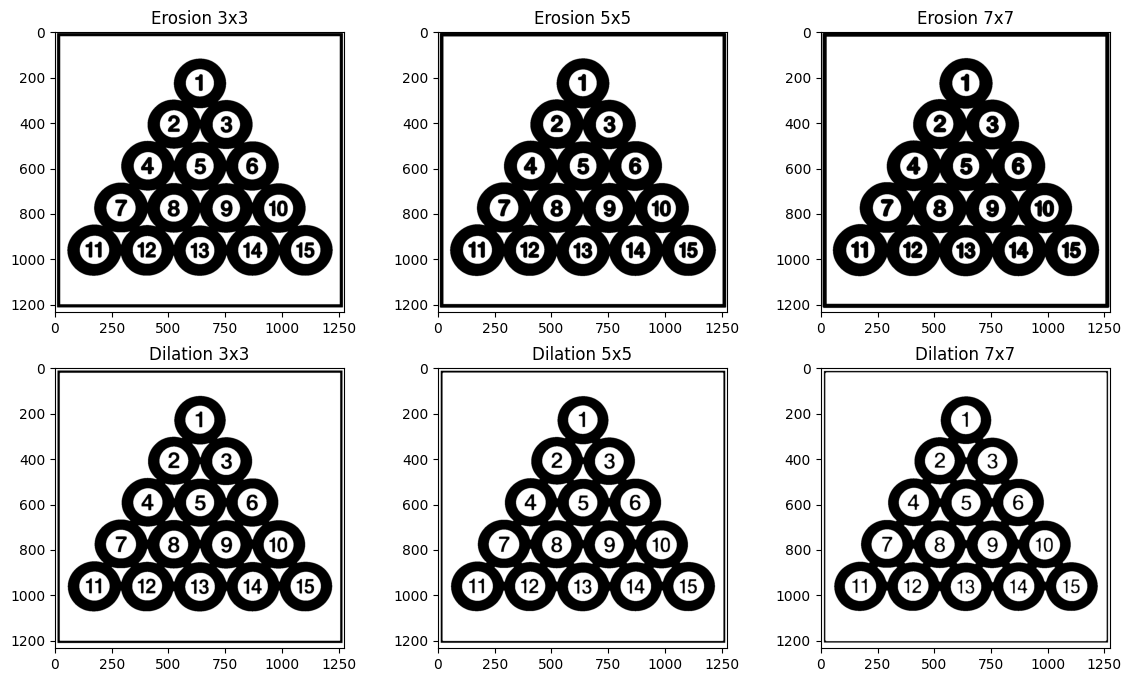

In [27]:
# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define cross kernels
kernel3 = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
kernel5 = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))
kernel7 = cv2.getStructuringElement(cv2.MORPH_CROSS, (7, 7))

# 4. Apply erosion and dilation
eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img5 = cv2.erode(binary, kernel5, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)

dilated_img3 = cv2.dilate(binary, kernel3, iterations=1)
dilated_img5 = cv2.dilate(binary, kernel5, iterations=1)
dilated_img7 = cv2.dilate(binary, kernel7, iterations=1)

# 5. Display comparison
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1), plt.imshow(eroded_img3, 'gray'), plt.title('Erosion 3x3')
plt.subplot(2, 3, 2), plt.imshow(eroded_img5, 'gray'), plt.title('Erosion 5x5')
plt.subplot(2, 3, 3), plt.imshow(eroded_img7, 'gray'), plt.title('Erosion 7x7')

plt.subplot(2, 3, 4), plt.imshow(dilated_img3, 'gray'), plt.title('Dilation 3x3')
plt.subplot(2, 3, 5), plt.imshow(dilated_img5, 'gray'), plt.title('Dilation 5x5')
plt.subplot(2, 3, 6), plt.imshow(dilated_img7, 'gray'), plt.title('Dilation 7x7')

plt.show()

# Ellipse Structuring Element

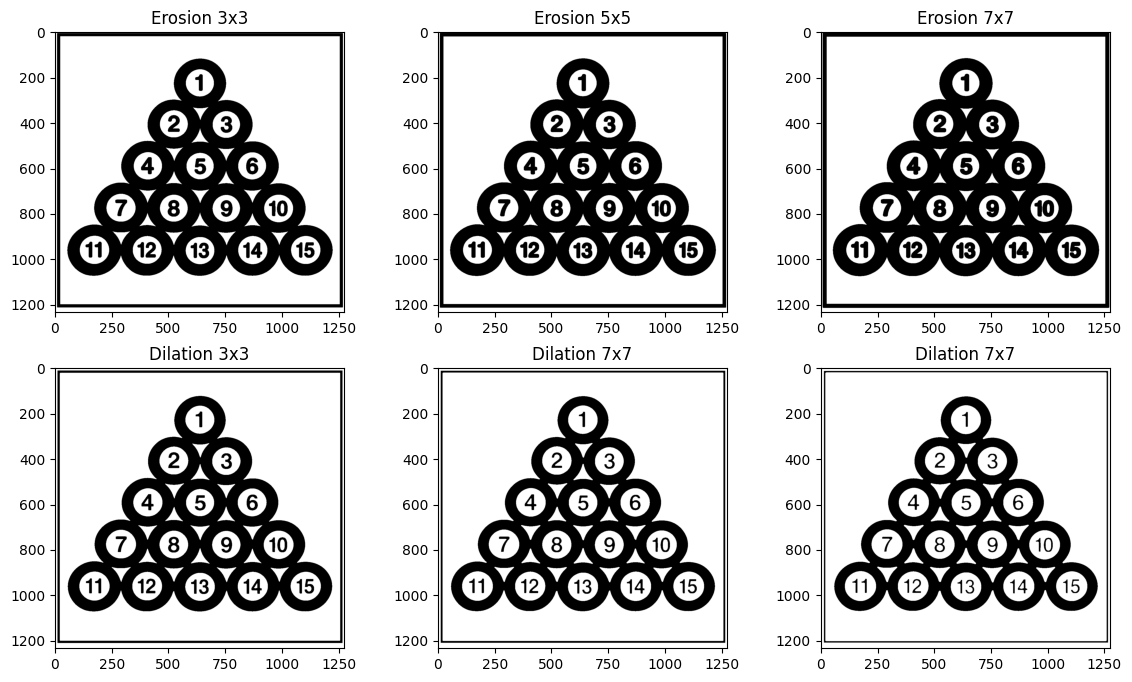

In [28]:
# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3. Define ellipse kernels
kernel3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
kernel5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
kernel7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

# 4. Apply erosion and dilation
eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img5 = cv2.erode(binary, kernel5, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)

dilated_img3 = cv2.dilate(binary, kernel3, iterations=1)
dilated_img5 = cv2.dilate(binary, kernel5, iterations=1)
dilated_img7 = cv2.dilate(binary, kernel7, iterations=1)

# 5. Display comparison
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1), plt.imshow(eroded_img3, 'gray'), plt.title('Erosion 3x3')
plt.subplot(2, 3, 2), plt.imshow(eroded_img5, 'gray'), plt.title('Erosion 5x5')
plt.subplot(2, 3, 3), plt.imshow(eroded_img7, 'gray'), plt.title('Erosion 7x7')

plt.subplot(2, 3, 4), plt.imshow(dilated_img3, 'gray'), plt.title('Dilation 3x3')
plt.subplot(2, 3, 5), plt.imshow(dilated_img5, 'gray'), plt.title('Dilation 7x7')
plt.subplot(2, 3, 6), plt.imshow(dilated_img7, 'gray'), plt.title('Dilation 7x7')

plt.show()

## ***Comparison of Results***

***1. Ero